# Experiment 7a — seq2seq diagnostic: does the sequence-to-sequence framing decorrelate residuals from LightGBM-MAE?

Companion to `kp-experiment-7a-tabular.ipynb`. The tabular notebook tests whether a
*different model class* (MLP vs tree) on the *same engineered features* decorrelates
residuals from LightGBM-MAE. This notebook tests the orthogonal question: does the
*sequence-to-sequence framing* — covariate sequence → target sequence, no per-row
engineering — extract signal the tabular projection necessarily misses?

The framing shift comes from the user's professor's 2026-05-27 comment that the
underlying task is best described as seq2seq translation, not per-hour regression on
known covariates. **Read `README.md` in this directory first** for the joint
interpretation table (the two notebooks' r values are read together).

What the architecture looks like at a glance:

```
encoder  (BiLSTM, L=336 past timesteps)
         input per step: [past_covariates(13), past_target(1), past_time(7), series_emb(16)]
         output: final hidden state h_enc

decoder  (LSTM, H=336 future timesteps, initialized from h_enc)
         input per step: [future_covariates(13), future_time(7), series_emb(16)]
         output: target at that timestep

loss     MAE on un-normalized predictions, all H positions equally weighted
```

Three deliberate design choices, all defensible against prior failures:

- **No engineered lag/lead/rolling features.** Network must use raw sequence; if it
  reproduces LightGBM's residuals, the engineered features were already capturing
  everything the temporal axis has to offer.
- **No target-lag feedback to the decoder.** Encoder uses real past target (data
  available at inference); decoder emits all 336 hours from future covariates alone.
  This is the explicit break from experiments 1–3.1.
- **Direct multi-step output.** All 336 hours predicted in one forward pass.
  No rollout, no error compounding.


---
## §0. Configuration

Mirrors `kp-experiment-7a-tabular.ipynb` §0 for the parts that *must* match (paths,
LightGBM baseline, CV setup, decision thresholds) and adds the seq2seq-specific
hyperparameters in the second block.


In [1]:
from pathlib import Path

# ── Paths (same as tabular notebook) ─────────────────────────────────────────
DATA_DIR     = Path("/kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data")
OUTPUT_DIR   = Path("/kaggle/working")
# Local:
# DATA_DIR     = Path("../data")
# OUTPUT_DIR   = Path(".")

TRAIN_PATH     = DATA_DIR / "train.csv"
VAL_INPUT_PATH = DATA_DIR / "validation_input.csv"
VAL_INDEX_PATH = DATA_DIR / "forecast_index_validation.csv"

# ── Reproducibility ──────────────────────────────────────────────────────────
SEED         = 42
N_FOLDS      = 3
EVAL_HORIZON = 336      # 14-day forecast window (hours)

# ── Feature columns (raw — no engineered lag/lead/rolling) ───────────────────
DOMAIN_FEAT_COLS = [
    "workload_intensity", "demand_forecast", "upstream_quality_forecast",
    "promotion_intensity", "shock_risk", "maintenance_known",
    "unit_reliability_forecast", "queue_pressure_forecast",
    "network_pressure_forecast", "event_load_forecast",
    "service_irregularity_risk_forecast",
]
TIME_COLS = ["hour_sin", "hour_cos", "dow_sin", "dow_cos",
             "doy_sin", "doy_cos", "is_weekend"]

# LightGBM baseline (exp-5.1 BASELINE_LGBM) — used to recompute OOF anchor in §4.
# We re-engineer the lag/lead features ONLY for the LGBM baseline; the seq2seq
# model below sees raw sequences.
TOP_DOM    = ["queue_pressure_forecast", "network_pressure_forecast",
              "workload_intensity", "shock_risk", "event_load_forecast"]
TOP3_ROLL  = TOP_DOM[:3]
LAGS_DOM   = [1, 24]
LEADS_DOM  = [1, 24]
ROLL_WINS  = [6, 24]
BASELINE_LGBM = dict(
    n_estimators=600, learning_rate=0.03, num_leaves=63,
    subsample=0.8, colsample_bytree=0.8, min_child_samples=50,
    reg_lambda=1.0, verbose=-1,
)

# ── Seq2seq config ──────────────────────────────────────────────────────────
SEQ_PAST_LEN     = 336   # L — past timesteps fed to encoder
SEQ_FUTURE_LEN   = 336   # H — future timesteps fed to decoder (matches eval horizon)

ENCODER_HIDDEN   = 128
DECODER_HIDDEN   = 128
ENCODER_LAYERS   = 2
DECODER_LAYERS   = 2
SEQ_DROPOUT      = 0.2
SEQ_EMBED_DIM    = 16    # series embedding dim

SEQ_BATCH        = 32
SEQ_LR           = 5e-4
SEQ_WEIGHT_DECAY = 1e-4
SEQ_EPOCHS       = 30
SEQ_EARLY_STOP   = 5
SEQ_GRAD_CLIP    = 1.0
SEQ_WINDOWS_PER_SERIES_PER_EPOCH = 4  # random window count drawn per series per epoch

SEQ_SEEDS        = [42, 101, 202]

# ── Decision thresholds — same as tabular notebook, stated up front ──────────
R_STRONG_DIVERSITY  = 0.85
R_FEATURE_BOUND     = 0.95

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"DATA_DIR    = {DATA_DIR}")
print(f"OUTPUT_DIR  = {OUTPUT_DIR}")
print(f"CV folds    : {N_FOLDS}, eval horizon: {EVAL_HORIZON}h")
print(f"Seq lens    : past {SEQ_PAST_LEN}h, future {SEQ_FUTURE_LEN}h "
      f"(total per window = {SEQ_PAST_LEN + SEQ_FUTURE_LEN}h)")
print(f"Encoder     : BiLSTM hidden {ENCODER_HIDDEN} × {ENCODER_LAYERS} layers, dropout {SEQ_DROPOUT}")
print(f"Decoder     : LSTM   hidden {DECODER_HIDDEN} × {DECODER_LAYERS} layers")
print(f"Train       : batch {SEQ_BATCH}, lr {SEQ_LR}, weight_decay {SEQ_WEIGHT_DECAY}, "
      f"epochs {SEQ_EPOCHS} (early stop {SEQ_EARLY_STOP}), grad clip {SEQ_GRAD_CLIP}")
print(f"Sampling    : {SEQ_WINDOWS_PER_SERIES_PER_EPOCH} windows/series/epoch, seeds {SEQ_SEEDS}")
print(f"Decision    : r < {R_STRONG_DIVERSITY} → strong diversity; r > {R_FEATURE_BOUND} → feature-bound")


DATA_DIR    = /kaggle/input/datasets/xitij27/dlam-bonus-project-dataset/data
OUTPUT_DIR  = /kaggle/working
CV folds    : 3, eval horizon: 336h
Seq lens    : past 336h, future 336h (total per window = 672h)
Encoder     : BiLSTM hidden 128 × 2 layers, dropout 0.2
Decoder     : LSTM   hidden 128 × 2 layers
Train       : batch 32, lr 0.0005, weight_decay 0.0001, epochs 30 (early stop 5), grad clip 1.0
Sampling    : 4 windows/series/epoch, seeds [42, 101, 202]
Decision    : r < 0.85 → strong diversity; r > 0.95 → feature-bound


---
## §1. Setup & Data Loading

Same data load + WAPE helper + device check as the tabular notebook.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb

import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.preprocessing import RobustScaler

np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch device: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

def wape(y_true, y_pred, eps=1e-8):
    return np.sum(np.abs(np.asarray(y_true) - np.asarray(y_pred))) / \
           (np.sum(np.abs(y_true)) + eps) * 100

train_df  = pd.read_csv(TRAIN_PATH,     parse_dates=["timestamp"])
val_input = pd.read_csv(VAL_INPUT_PATH, parse_dates=["timestamp"])
val_index = pd.read_csv(VAL_INDEX_PATH, parse_dates=["timestamp"])

sid_to_code = {sid: i for i, sid in enumerate(sorted(train_df["series_id"].unique()))}
N_SERIES = len(sid_to_code)

print(f"train_df : {train_df.shape}")
print(f"# series : {N_SERIES}")
print(f"hours/series in train_df: {len(train_df) // N_SERIES}")


PyTorch device: cuda
  GPU: Tesla T4
train_df : (414720, 25)
# series : 96
hours/series in train_df: 4320


---
## §2. Sequence preparation

Two completely separate feature pipelines live in this notebook:

1. **Tabular** (only for the LightGBM baseline in §4) — the exp-5.1 lag/lead/rolling
   pipeline. Necessary so that the LGBM OOF predictions in §4 match exp-5.1's
   numbers, anchoring the residual comparison in §7. Copy-paste of exp-5.1 §2.

2. **Sequential** (the actual seq2seq input) — raw per-timestep tensors. *No*
   engineered features. Per-series arrays of `(time, features)`, `(time, target)`,
   `(time, time_encodings)` that the model indexes into via `(start, length)`
   slicing. This is what isolates the framing variable.

Per-series arrays are built once and reused across folds — only the
fold-specific normalization stats change per fold (§5).


In [3]:
# ── Tabular pipeline for LGBM baseline (verbatim from exp-5.1) ──────────────
def impute_domain_features(df, cols):
    df = df.sort_values(["series_id", "timestamp"]).copy()
    df[cols] = df.groupby("series_id", group_keys=False)[cols].transform(
        lambda x: x.ffill().bfill()
    )
    return df

def add_time_features(df, time_col="timestamp"):
    df = df.copy()
    t = pd.to_datetime(df[time_col])
    df["hour_sin"]   = np.sin(2 * np.pi * t.dt.hour / 24)
    df["hour_cos"]   = np.cos(2 * np.pi * t.dt.hour / 24)
    df["dow_sin"]    = np.sin(2 * np.pi * t.dt.dayofweek / 7)
    df["dow_cos"]    = np.cos(2 * np.pi * t.dt.dayofweek / 7)
    df["doy_sin"]    = np.sin(2 * np.pi * t.dt.dayofyear / 365)
    df["doy_cos"]    = np.cos(2 * np.pi * t.dt.dayofyear / 365)
    df["is_weekend"] = (t.dt.dayofweek >= 5).astype(float)
    return df

def add_temporal_features(df, lag_cols, roll_cols, lags, leads, windows):
    df = df.copy().sort_values(["series_id", "timestamp"])
    new = []
    for col in lag_cols:
        g = df.groupby("series_id", sort=False)[col]
        for L in lags:
            c = f"{col}_lag{L}";  df[c] = g.shift(L);  new.append(c)
        for L in leads:
            c = f"{col}_lead{L}"; df[c] = g.shift(-L); new.append(c)
    for col in roll_cols:
        g = df.groupby("series_id", sort=False)[col]
        for W in windows:
            c_m = f"{col}_roll{W}m"
            df[c_m] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).mean())
            new.append(c_m)
            c_s = f"{col}_roll{W}s"
            df[c_s] = g.shift(1).transform(lambda x: x.rolling(W, min_periods=1).std().fillna(0))
            new.append(c_s)
    return df, new

base = add_time_features(impute_domain_features(train_df, DOMAIN_FEAT_COLS))
base["sid_code"] = base["series_id"].map(sid_to_code).astype("int32")
base, TEMPORAL_FEATS = add_temporal_features(
    base, lag_cols=TOP_DOM, roll_cols=TOP3_ROLL,
    lags=LAGS_DOM, leads=LEADS_DOM, windows=ROLL_WINS,
)
NUMERIC_FEATS  = DOMAIN_FEAT_COLS + TIME_COLS + ["series_mean"] + TEMPORAL_FEATS
FEATS_WITH_SID = NUMERIC_FEATS + ["sid_code"]
print(f"Tabular features (for LGBM baseline): {len(FEATS_WITH_SID)}")

# ── Sequential pipeline (the actual seq2seq input) ───────────────────────────
# Build per-series 2-D arrays of (timesteps, features), (timesteps,) for target,
# (timesteps, 7) for time encodings. These are dense (no NaN — the imputation in
# `base` already handled it). We use them by indexing [start:start+L] for windows.

def build_series_arrays(base_df):
    "Return dict: sid (int code) -> (covariates[T,F], target[T], time[T,7], timestamps[T])."
    out = {}
    for sid_code, g in base_df.sort_values(["sid_code", "timestamp"]).groupby("sid_code", sort=True):
        g = g.reset_index(drop=True)
        covariates = g[DOMAIN_FEAT_COLS].to_numpy(np.float32)   # (T, 13)  -- 11 + 2 zero-NaN columns
        target     = g["target"].to_numpy(np.float32)            # (T,)
        time_feat  = g[TIME_COLS].to_numpy(np.float32)           # (T, 7)
        timestamps = g["timestamp"].to_numpy()
        out[int(sid_code)] = dict(cov=covariates, tgt=target, tim=time_feat, ts=timestamps)
    return out

# Use *only* the original 11 forecast columns for sequence input (matches
# DOMAIN_FEAT_COLS — engineered lags do not appear here on purpose).
SERIES_ARR = build_series_arrays(base)
T_PER_SERIES = next(iter(SERIES_ARR.values()))["cov"].shape[0]
F_RAW = len(DOMAIN_FEAT_COLS)
F_TIME = len(TIME_COLS)
print(f"\nSequential per-series arrays:")
print(f"  T per series : {T_PER_SERIES}")
print(f"  F covariates : {F_RAW}")
print(f"  F time enc.  : {F_TIME}")
print(f"  Encoder input dim/step : {F_RAW + 1 + F_TIME + SEQ_EMBED_DIM} "
      f"  (covariates + past_target + time + series_emb)")
print(f"  Decoder input dim/step : {F_RAW + F_TIME + SEQ_EMBED_DIM} "
      f"  (future_covariates + future_time + series_emb)")


Tabular features (for LGBM baseline): 52

Sequential per-series arrays:
  T per series : 4320
  F covariates : 11
  F time enc.  : 7
  Encoder input dim/step : 35   (covariates + past_target + time + series_emb)
  Decoder input dim/step : 34   (future_covariates + future_time + series_emb)


---
## §3. CV framework + window utilities

Same `fold_split` / `fold_offset` as the other Phase 7 notebook (and exp-5.1). For
the seq2seq pipeline we additionally need window-sampling utilities — given a fold,
which `(series, start)` pairs are valid for sampling a `(past=L, future=H)` window
from the *training* portion only? And what is the single window we use at evaluation
time to predict the test block?


In [4]:
def fold_split(end_off, length=EVAL_HORIZON):
    "Split `base` into (train, test) — used by the LGBM baseline in §4."
    tr_list, te_list = [], []
    for _, g in base.groupby("series_id", sort=False):
        g = g.sort_values("timestamp")
        cut = len(g) - end_off
        tr_list.append(g.iloc[:cut])
        te_list.append(g.iloc[cut:cut + length])
    tr = pd.concat(tr_list, ignore_index=True)
    te = pd.concat(te_list, ignore_index=True)
    sm = tr.groupby("series_id")["target"].mean().rename("series_mean").reset_index()
    return tr.merge(sm, on="series_id"), te.merge(sm, on="series_id")

def fold_offset(k):
    return (N_FOLDS - k) * EVAL_HORIZON


# ── Seq2seq fold structure ──────────────────────────────────────────────────
# For fold k (end_off = fold_offset(k)):
#   train_end_idx = T_PER_SERIES - end_off            (last index of training slice)
#   test_start    = train_end_idx
#   test_end      = train_end_idx + EVAL_HORIZON
#
# Evaluation window: past = [train_end_idx - L : train_end_idx]
#                    future = [train_end_idx : train_end_idx + H]
#
# Training window for sampling: any start in [0, train_end_idx - L - H].
#   past   = [start : start + L]
#   future = [start + L : start + L + H]
# (Both fully inside the training slice; no leakage from the test block.)

def fold_train_end_idx(k):
    return T_PER_SERIES - fold_offset(k)

def fold_valid_train_window_starts(k):
    "Range of valid start indices for sampling training windows in fold k."
    end_idx = fold_train_end_idx(k)
    max_start = end_idx - SEQ_PAST_LEN - SEQ_FUTURE_LEN
    return 0, max_start

def fold_eval_window(k):
    "Return (past_start, past_end, future_start, future_end) for fold k. Future window IS the test block."
    end_idx = fold_train_end_idx(k)
    return (end_idx - SEQ_PAST_LEN, end_idx, end_idx, end_idx + SEQ_FUTURE_LEN)


for k in range(N_FOLDS):
    lo, hi = fold_valid_train_window_starts(k)
    pe = fold_eval_window(k)
    print(f"Fold {k}: train_end_idx={fold_train_end_idx(k)}, "
          f"train-window starts in [{lo}, {hi}] "
          f"({hi - lo + 1} possible per series), "
          f"eval future = [{pe[2]}, {pe[3]})")


Fold 0: train_end_idx=3312, train-window starts in [0, 2640] (2641 possible per series), eval future = [3312, 3648)
Fold 1: train_end_idx=3648, train-window starts in [0, 2976] (2977 possible per series), eval future = [3648, 3984)
Fold 2: train_end_idx=3984, train-window starts in [0, 3312] (3313 possible per series), eval future = [3984, 4320)


---
## §4. LightGBM-MAE baseline — recompute OOF anchor

Reproduce exp-5.1's LightGBM-MAE pipeline to get fresh OOF predictions. These are
the residual anchor for §7. Re-running here (instead of loading
`oof_predictions_7a_tabular.csv` from the companion notebook) means LightGBM and
seq2seq see byte-identical fold splits — no risk of drift from any minor change
in data-load order between the two notebooks.

Must land at CV-WAPE ~14.78 ± 0.6. If not, stop.


In [5]:
def fit_lgbm_predict(tr, te, feats, params, objective, categorical=None, seed=SEED):
    model = lgb.LGBMRegressor(**params, objective=objective, random_state=seed)
    fit_kw = {} if not categorical else {"categorical_feature": categorical}
    model.fit(tr[feats], tr["target"].to_numpy(float), **fit_kw)
    return model.predict(te[feats]), model

print("Running LightGBM-MAE baseline (same config as exp-5.1)...")
oof_lgbm_rows = []
per_fold_lgbm = []
for k in range(N_FOLDS):
    tr, te = fold_split(fold_offset(k))
    preds, _ = fit_lgbm_predict(tr, te, FEATS_WITH_SID, BASELINE_LGBM,
                                  "regression_l1", categorical=["sid_code"])
    per_fold_lgbm.append(wape(te["target"], preds))
    oof_lgbm_rows.append(te.assign(pred_lgbm=preds, fold=k)[
        ["series_id","timestamp","target","pred_lgbm","fold"]
    ])
oof_lgbm = pd.concat(oof_lgbm_rows, ignore_index=True)
lgbm_arr = np.array(per_fold_lgbm)

print()
print(f"{'fold':>6}  {'WAPE':>8}")
for k, w in enumerate(lgbm_arr): print(f"  {k:4d}    {w:>7.3f}")
print(f"  ────")
print(f"  mean    {lgbm_arr.mean():>7.3f}")
print(f"  std     {lgbm_arr.std():>7.3f}")
LGBM_WAPE = lgbm_arr.mean()
LGBM_STD  = lgbm_arr.std()

if abs(LGBM_WAPE - 14.78) < 0.5:
    print(f"\n✅ LGBM baseline reproduces exp-5.1 (within 0.5 of 14.78).")
else:
    print(f"\n⚠️  LGBM baseline = {LGBM_WAPE:.3f}, off exp-5.1's 14.78 by "
          f"{abs(LGBM_WAPE - 14.78):.2f}. Investigate before continuing.")


Running LightGBM-MAE baseline (same config as exp-5.1)...

  fold      WAPE
     0     14.082
     1     15.581
     2     14.683
  ────
  mean     14.782
  std       0.616

✅ LGBM baseline reproduces exp-5.1 (within 0.5 of 14.78).


---
## §5. Encoder-Decoder LSTM — architecture and training utilities

The model maps `(past covariates, past target, past time) → (future covariates,
future time) → future target sequence`. Key implementation details:

- **Per-fold normalization is applied at the tensor level.** Domain features are
  scaled with `RobustScaler` fit on the fold's training slice only; the target is
  per-series standardized `(y − μ_s) / σ_s` with `μ_s, σ_s` from the training slice
  too. Past target is fed to the encoder *in normalized units*; model predictions
  come out in normalized units; we un-normalize before computing MAE so the loss
  matches WAPE (which lives in original units).
- **BiLSTM encoder.** Forward and backward LSTM concat outputs at each step; only
  the final state is consumed by the decoder via a learned linear projection
  `2*hidden → hidden`. This is the standard NMT-style seq2seq plumbing.
- **Direct multi-step decoder.** Decoder runs over all H future timesteps in one
  pass (PyTorch's nn.LSTM does this internally); the final linear head projects
  per-step hidden to a scalar. No autoregressive loop, no target feedback.
- **Gradient clipping at 1.0.** Standard hygiene for LSTM training.


In [6]:
class Seq2SeqLSTM(nn.Module):
    "Encoder-decoder LSTM. Maps covariate sequence -> target sequence."

    def __init__(self, n_features, n_time, n_series, embed_dim,
                 hidden_dim, n_enc_layers, n_dec_layers, dropout):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.n_dec_layers = n_dec_layers
        self.series_emb = nn.Embedding(n_series, embed_dim)

        enc_input_dim = n_features + 1 + n_time + embed_dim   # +1 for past_target
        dec_input_dim = n_features + n_time + embed_dim

        self.encoder = nn.LSTM(
            enc_input_dim, hidden_dim, num_layers=n_enc_layers,
            batch_first=True, bidirectional=True,
            dropout=dropout if n_enc_layers > 1 else 0.0,
        )
        # Project encoder's bidirectional final state (n_enc_layers*2, B, hidden) to
        # decoder's initial state (n_dec_layers, B, hidden). One linear per state
        # (h and c), shared across decoder layers via repeat — simple and effective.
        self.proj_h = nn.Linear(2 * hidden_dim, hidden_dim)
        self.proj_c = nn.Linear(2 * hidden_dim, hidden_dim)

        self.decoder = nn.LSTM(
            dec_input_dim, hidden_dim, num_layers=n_dec_layers,
            batch_first=True, bidirectional=False,
            dropout=dropout if n_dec_layers > 1 else 0.0,
        )
        self.head = nn.Linear(hidden_dim, 1)

    def forward(self, past_cov, past_tgt, past_tim, future_cov, future_tim, sid):
        # Args: past_cov (B,L,F), past_tgt (B,L) already-normalized,
        # past_tim (B,L,T_d), future_cov (B,H,F), future_tim (B,H,T_d), sid (B,) long.
        # Returns: normalized predictions (B, H).
        B, L, _ = past_cov.shape
        H = future_cov.shape[1]

        e = self.series_emb(sid)                                # (B, embed)
        e_past   = e.unsqueeze(1).expand(B, L, -1)
        e_future = e.unsqueeze(1).expand(B, H, -1)

        enc_in = torch.cat([past_cov, past_tgt.unsqueeze(-1), past_tim, e_past], dim=-1)
        _, (h_enc, c_enc) = self.encoder(enc_in)
        # h_enc: (n_enc_layers*2, B, hidden) — bidirectional
        # Combine forward+backward by concat on the hidden dim, average across layers,
        # then broadcast to decoder layers.
        n_enc = h_enc.shape[0] // 2
        h_bi = h_enc.view(n_enc, 2, B, -1).permute(0, 2, 1, 3).reshape(n_enc, B, -1)
        c_bi = c_enc.view(n_enc, 2, B, -1).permute(0, 2, 1, 3).reshape(n_enc, B, -1)
        h_last = h_bi.mean(dim=0)                                # (B, 2*hidden)
        c_last = c_bi.mean(dim=0)
        h_dec0 = self.proj_h(h_last).unsqueeze(0).expand(self.n_dec_layers, -1, -1).contiguous()
        c_dec0 = self.proj_c(c_last).unsqueeze(0).expand(self.n_dec_layers, -1, -1).contiguous()

        dec_in = torch.cat([future_cov, future_tim, e_future], dim=-1)
        out, _ = self.decoder(dec_in, (h_dec0, c_dec0))
        return self.head(out).squeeze(-1)                        # (B, H)


def fit_fold_normalizers(k):
    "Compute per-fold normalization: RobustScaler on training covariates, per-series mu/sd of target."
    end_idx = fold_train_end_idx(k)
    all_cov = np.concatenate([SERIES_ARR[s]["cov"][:end_idx] for s in range(N_SERIES)], axis=0)
    feat_scaler = RobustScaler().fit(all_cov)
    mu = np.zeros(N_SERIES, dtype=np.float32)
    sd = np.zeros(N_SERIES, dtype=np.float32)
    for s in range(N_SERIES):
        tgt_tr = SERIES_ARR[s]["tgt"][:end_idx]
        mu[s] = float(tgt_tr.mean())
        sd[s] = max(float(tgt_tr.std()), 1e-3)
    return feat_scaler, mu, sd


def transform_series(k, feat_scaler, mu, sd):
    "Apply fold-specific transforms to every series, return dict of normalized arrays."
    out = {}
    for s in range(N_SERIES):
        arr = SERIES_ARR[s]
        cov_norm = feat_scaler.transform(arr["cov"]).astype(np.float32)
        cov_norm = np.nan_to_num(cov_norm, nan=0.0)
        tgt_norm = ((arr["tgt"] - mu[s]) / sd[s]).astype(np.float32)
        out[s] = dict(cov=cov_norm, tgt_norm=tgt_norm, tgt_raw=arr["tgt"],
                      tim=arr["tim"], ts=arr["ts"])
    return out


def sample_training_batch(k, transformed, rng, batch_size):
    "Sample (series, start) windows from training portion of fold k; returns tensors for forward+loss."
    lo, hi = fold_valid_train_window_starts(k)
    L, H = SEQ_PAST_LEN, SEQ_FUTURE_LEN

    past_cov_list, past_tgt_list, past_tim_list = [], [], []
    fut_cov_list,  fut_tim_list                  = [], []
    sid_list, target_orig_list                   = [], []
    mu_list,  sd_list                            = [], []

    for _ in range(batch_size):
        s = int(rng.integers(0, N_SERIES))
        start = int(rng.integers(lo, hi + 1))
        a = transformed[s]
        past_cov_list.append(a["cov"][start : start + L])
        past_tgt_list.append(a["tgt_norm"][start : start + L])
        past_tim_list.append(a["tim"][start : start + L])
        fut_cov_list .append(a["cov"][start + L : start + L + H])
        fut_tim_list .append(a["tim"][start + L : start + L + H])
        target_orig_list.append(a["tgt_raw"][start + L : start + L + H])
        sid_list.append(s)

    return dict(
        past_cov   = torch.from_numpy(np.stack(past_cov_list)),
        past_tgt   = torch.from_numpy(np.stack(past_tgt_list)),
        past_tim   = torch.from_numpy(np.stack(past_tim_list)),
        fut_cov    = torch.from_numpy(np.stack(fut_cov_list)),
        fut_tim    = torch.from_numpy(np.stack(fut_tim_list)),
        sid        = torch.tensor(sid_list, dtype=torch.long),
        target_orig= torch.from_numpy(np.stack(target_orig_list)),
    )


def build_eval_batch(k, transformed):
    "Build batch over all 96 series; one (past, future) window per series, future window = test block."
    L, H = SEQ_PAST_LEN, SEQ_FUTURE_LEN
    past_start, past_end, fut_start, fut_end = fold_eval_window(k)
    past_cov_list, past_tgt_list, past_tim_list = [], [], []
    fut_cov_list,  fut_tim_list                  = [], []
    sid_list, target_orig_list, ts_list          = [], [], []
    for s in range(N_SERIES):
        a = transformed[s]
        past_cov_list.append(a["cov"][past_start : past_end])
        past_tgt_list.append(a["tgt_norm"][past_start : past_end])
        past_tim_list.append(a["tim"][past_start : past_end])
        fut_cov_list .append(a["cov"][fut_start : fut_end])
        fut_tim_list .append(a["tim"][fut_start : fut_end])
        target_orig_list.append(a["tgt_raw"][fut_start : fut_end])
        ts_list.append(a["ts"][fut_start : fut_end])
        sid_list.append(s)
    return dict(
        past_cov   = torch.from_numpy(np.stack(past_cov_list)),
        past_tgt   = torch.from_numpy(np.stack(past_tgt_list)),
        past_tim   = torch.from_numpy(np.stack(past_tim_list)),
        fut_cov    = torch.from_numpy(np.stack(fut_cov_list)),
        fut_tim    = torch.from_numpy(np.stack(fut_tim_list)),
        sid        = torch.tensor(sid_list, dtype=torch.long),
        target_orig= torch.from_numpy(np.stack(target_orig_list)),
        timestamps = np.stack(ts_list),
        series_ids = [s for s in range(N_SERIES)],
    )


def train_seq2seq_one_seed(k, transformed, mu, sd, seed):
    "Train one model on fold k, return (predictions_original_units (96, H), timestamps, sids)."
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    model = Seq2SeqLSTM(
        n_features=F_RAW, n_time=F_TIME, n_series=N_SERIES,
        embed_dim=SEQ_EMBED_DIM, hidden_dim=ENCODER_HIDDEN,
        n_enc_layers=ENCODER_LAYERS, n_dec_layers=DECODER_LAYERS,
        dropout=SEQ_DROPOUT,
    ).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SEQ_LR, weight_decay=SEQ_WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=SEQ_EPOCHS)

    # Inner-val batch: sample (and freeze) a fixed batch from the END of the
    # training slice for early stopping. This is *inside* the training slice — not
    # the test block — so still leakage-free.
    val_rng = np.random.default_rng(seed + 10_000)
    val_batch = sample_training_batch(k, transformed, val_rng, batch_size=64)

    mu_t = torch.tensor(mu, device=DEVICE)
    sd_t = torch.tensor(sd, device=DEVICE)

    def loss_on_batch(b):
        past_cov = b["past_cov"].to(DEVICE)
        past_tgt = b["past_tgt"].to(DEVICE)
        past_tim = b["past_tim"].to(DEVICE)
        fut_cov  = b["fut_cov"].to(DEVICE)
        fut_tim  = b["fut_tim"].to(DEVICE)
        sid      = b["sid"].to(DEVICE)
        target_o = b["target_orig"].to(DEVICE)
        pred_norm = model(past_cov, past_tgt, past_tim, fut_cov, fut_tim, sid)
        # Un-normalize predictions to original units, then MAE
        sid_mu = mu_t[sid].unsqueeze(1)
        sid_sd = sd_t[sid].unsqueeze(1)
        pred_orig = pred_norm * sid_sd + sid_mu
        return F.l1_loss(pred_orig, target_o)

    best_val = float("inf"); patience = 0; best_state = None
    steps_per_epoch = max(1, (N_SERIES * SEQ_WINDOWS_PER_SERIES_PER_EPOCH) // SEQ_BATCH)

    for epoch in range(SEQ_EPOCHS):
        model.train()
        for _ in range(steps_per_epoch):
            batch = sample_training_batch(k, transformed, rng, SEQ_BATCH)
            opt.zero_grad()
            loss = loss_on_batch(batch)
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), SEQ_GRAD_CLIP)
            opt.step()
        sched.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_on_batch(val_batch).item()

        if val_loss < best_val - 1e-4:
            best_val = val_loss; patience = 0
            best_state = {k_: v.detach().cpu().clone() for k_, v in model.state_dict().items()}
        else:
            patience += 1
            if patience >= SEQ_EARLY_STOP:
                break

    if best_state is not None:
        model.load_state_dict(best_state)

    model.eval()
    eval_batch = build_eval_batch(k, transformed)
    with torch.no_grad():
        pred_norm = model(
            eval_batch["past_cov"].to(DEVICE),
            eval_batch["past_tgt"].to(DEVICE),
            eval_batch["past_tim"].to(DEVICE),
            eval_batch["fut_cov"].to(DEVICE),
            eval_batch["fut_tim"].to(DEVICE),
            eval_batch["sid"].to(DEVICE),
        ).cpu().numpy()
    sid_mu = mu[eval_batch["sid"].numpy()][:, None]
    sid_sd = sd[eval_batch["sid"].numpy()][:, None]
    pred_orig = pred_norm * sid_sd + sid_mu
    pred_orig = np.clip(pred_orig, 0, None)
    return pred_orig, eval_batch["timestamps"], eval_batch["series_ids"], eval_batch["target_orig"].numpy()


print(f"Seq2seq utilities ready. "
      f"Model params (rough): "
      f"{F_RAW + 1 + F_TIME + SEQ_EMBED_DIM} → {ENCODER_HIDDEN} BiLSTM × {ENCODER_LAYERS} "
      f"→ {DECODER_HIDDEN} LSTM × {DECODER_LAYERS} → 1")


Seq2seq utilities ready. Model params (rough): 35 → 128 BiLSTM × 2 → 128 LSTM × 2 → 1


---
## §6. Seq2seq CV — 3 folds × 3 seeds

Same 3-fold structure as everything in Phase 5+6, with multi-seed averaging
(3 seeds, matching the tabular notebook). Expected runtime: ~25 min on T4,
~1.5 hours on CPU.


In [7]:
import time

# Map back from sid_code to series_id string for the OOF CSV.
code_to_sid = {v: k for k, v in sid_to_code.items()}

oof_seq_rows = []
per_fold_seq = []
per_fold_seed_spread = []

for k in range(N_FOLDS):
    fold_start = time.time()
    feat_scaler, mu, sd = fit_fold_normalizers(k)
    transformed = transform_series(k, feat_scaler, mu, sd)

    seed_preds_2d = []   # list of (96, H) arrays
    for s in SEQ_SEEDS:
        p, ts_arr, sids, target_orig = train_seq2seq_one_seed(k, transformed, mu, sd, seed=s)
        seed_preds_2d.append(p)

    seed_arr  = np.stack(seed_preds_2d, axis=0)              # (n_seeds, 96, H)
    avg_pred  = seed_arr.mean(axis=0)                        # (96, H)

    per_seed_wapes = []
    for i in range(len(SEQ_SEEDS)):
        # Flatten across series and horizon to compute WAPE on the test block
        per_seed_wapes.append(wape(target_orig.flatten(), seed_arr[i].flatten()))
    spread = max(per_seed_wapes) - min(per_seed_wapes)
    fold_wape = wape(target_orig.flatten(), avg_pred.flatten())
    per_fold_seq.append(fold_wape)
    per_fold_seed_spread.append(spread)

    # Flatten predictions into OOF rows
    for sidx, sid_code_int in enumerate(sids):
        sid_str = code_to_sid[sid_code_int]
        for h in range(avg_pred.shape[1]):
            oof_seq_rows.append({
                "series_id": sid_str,
                "timestamp": ts_arr[sidx, h],
                "target":    float(target_orig[sidx, h]),
                "pred_seq":  float(avg_pred[sidx, h]),
                "lead_h":    h + 1,
                "fold":      k,
            })

    print(f"  fold {k}: per-seed WAPEs {['%.3f' % w for w in per_seed_wapes]}, "
          f"avg = {fold_wape:.3f}, spread = {spread:.3f}, "
          f"time = {time.time()-fold_start:.1f}s")

oof_seq = pd.DataFrame(oof_seq_rows)
seq_arr = np.array(per_fold_seq)
SEQ_WAPE = seq_arr.mean()
SEQ_STD  = seq_arr.std()

print()
print(f"{'fold':>6}  {'WAPE':>8}  {'seed spread':>12}")
for k, (w, sp) in enumerate(zip(seq_arr, per_fold_seed_spread)):
    print(f"  {k:4d}    {w:>7.3f}    {sp:>10.3f}")
print(f"  ────")
print(f"  mean    {SEQ_WAPE:>7.3f}")
print(f"  std     {SEQ_STD:>7.3f}")

print()
print(f"LightGBM-MAE (§4) : {LGBM_WAPE:.3f} ± {LGBM_STD:.3f}")
print(f"Seq2seq      (§6) : {SEQ_WAPE:.3f} ± {SEQ_STD:.3f}")
print(f"Solo gap          : {SEQ_WAPE - LGBM_WAPE:+.3f} WAPE")

if max(per_fold_seed_spread) > 2.5:
    print()
    print(f"⚠️  Max seed spread = {max(per_fold_seed_spread):.2f} WAPE — high variance.")
    print( "    Consider more seeds or longer training before fully trusting r in §7.")
if SEQ_WAPE > 25:
    print()
    print(f"⚠️  Seq2seq solo WAPE > 25 — model failed to converge.")
    print( "    Investigate before trusting §7's correlation number.")


  fold 0: per-seed WAPEs ['15.948', '15.570', '15.578'], avg = 15.503, spread = 0.377, time = 36.4s
  fold 1: per-seed WAPEs ['17.369', '17.350', '17.280'], avg = 17.117, spread = 0.089, time = 31.2s
  fold 2: per-seed WAPEs ['16.531', '16.498', '16.419'], avg = 16.276, spread = 0.112, time = 32.4s

  fold      WAPE   seed spread
     0     15.503         0.377
     1     17.117         0.089
     2     16.276         0.112
  ────
  mean     16.299
  std       0.659

LightGBM-MAE (§4) : 14.782 ± 0.616
Seq2seq      (§6) : 16.299 ± 0.659
Solo gap          : +1.517 WAPE


---
## §7. Residual correlation diagnostic — the headline

Pearson `r(residual_LGBM, residual_seq2seq)` on pooled OOF predictions. Same
decision rules as the tabular notebook — `r < 0.85` → strong diversity,
`r > 0.95` → seq2seq framing did not help on this dataset.


=== Pearson r(residual_LGBM, residual_seq2seq) ===
  fold        r
     0    0.9585
     1    0.9497
     2    0.9582
  ────
  pooled  0.9557


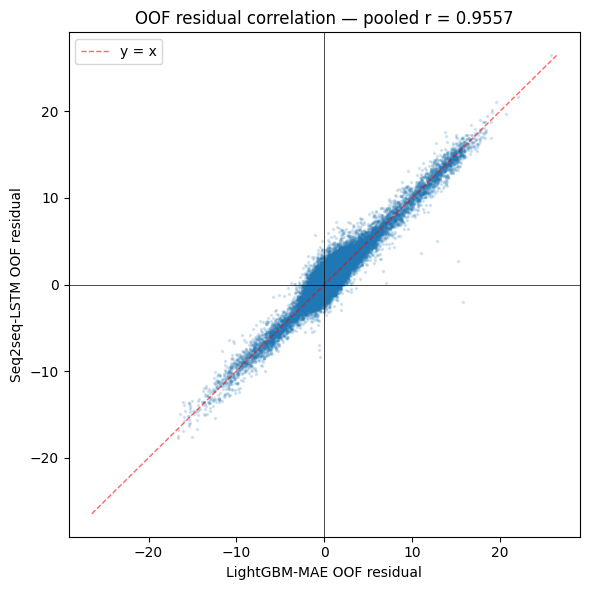


=== Decision ===
⚠️  r = 0.9557 > 0.95 — FEATURE-BOUND on the temporal axis too.
   The seq2seq framing did not unlock new signal on this dataset.
   Read this together with r_tabular from the companion notebook —
   see Phase 7 README joint-interpretation table.

OOF predictions saved → /kaggle/working/oof_predictions_7a_seq2seq.csv


In [8]:
# Merge LGBM and seq2seq OOF on (series_id, timestamp, fold).
joined = oof_lgbm.merge(
    oof_seq[["series_id", "timestamp", "pred_seq", "lead_h", "fold"]],
    on=["series_id", "timestamp", "fold"], how="inner",
)
assert len(joined) == len(oof_lgbm), \
    f"OOF row counts differ ({len(joined)} vs {len(oof_lgbm)}) — fold splits diverged. STOP."

joined["resid_lgbm"] = joined["target"] - joined["pred_lgbm"]
joined["resid_seq"]  = joined["target"] - joined["pred_seq"]

r_overall = np.corrcoef(joined["resid_lgbm"], joined["resid_seq"])[0, 1]
r_per_fold = []
for k in range(N_FOLDS):
    f = joined[joined["fold"] == k]
    r_per_fold.append(np.corrcoef(f["resid_lgbm"], f["resid_seq"])[0, 1])

print("=== Pearson r(residual_LGBM, residual_seq2seq) ===")
print(f"{'fold':>6}  {'r':>7}")
for k, r in enumerate(r_per_fold):
    print(f"  {k:>4}    {r:>6.4f}")
print(f"  ────")
print(f"  pooled  {r_overall:>6.4f}")

plt.figure(figsize=(6, 6))
sample = joined.sample(min(50_000, len(joined)), random_state=SEED)
plt.scatter(sample["resid_lgbm"], sample["resid_seq"], s=2, alpha=0.15)
lim = max(joined["resid_lgbm"].abs().max(), joined["resid_seq"].abs().max())
plt.plot([-lim, lim], [-lim, lim], "r--", lw=1, alpha=0.6, label="y = x")
plt.axhline(0, color="k", lw=0.5); plt.axvline(0, color="k", lw=0.5)
plt.xlabel("LightGBM-MAE OOF residual")
plt.ylabel("Seq2seq-LSTM OOF residual")
plt.title(f"OOF residual correlation — pooled r = {r_overall:.4f}")
plt.legend(); plt.tight_layout(); plt.show()

print()
print("=== Decision ===")
if r_overall < R_STRONG_DIVERSITY:
    print(f"✅ r = {r_overall:.4f} < {R_STRONG_DIVERSITY} — STRONG DIVERSITY.")
    print("   The seq2seq framing extracts signal LightGBM's per-row view didn't.")
    print("   Next: experiment-7c (LGBM + seq2seq blend), then experiment-7b (TiDE).")
    DECISION = "strong_diversity"
elif r_overall > R_FEATURE_BOUND:
    print(f"⚠️  r = {r_overall:.4f} > {R_FEATURE_BOUND} — FEATURE-BOUND on the temporal axis too.")
    print("   The seq2seq framing did not unlock new signal on this dataset.")
    print("   Read this together with r_tabular from the companion notebook —")
    print("   see Phase 7 README joint-interpretation table.")
    DECISION = "feature_bound"
else:
    print(f"~  r = {r_overall:.4f} — MODERATE diversity ({R_STRONG_DIVERSITY} ≤ r ≤ {R_FEATURE_BOUND}).")
    print("   Worth testing the blend (experiment-7c) — TiDE should produce lower r.")
    DECISION = "moderate_diversity"

out_path = OUTPUT_DIR / "oof_predictions_7a_seq2seq.csv"
joined[["series_id", "timestamp", "target", "pred_lgbm", "pred_seq", "lead_h", "fold"]].to_csv(
    out_path, index=False
)
print(f"\nOOF predictions saved → {out_path}")


---
## §8. Per-horizon WAPE diagnostic

Sequence-aware models should show approximately *flat* WAPE across the
336-hour horizon — the encoder's signal stays useful even for far-future
predictions. A model that degrades sharply at long horizons is behaving like
a per-step regressor with a sequence-shaped wrapper.

This diagnostic does not change §7's decision; it explains *why* the result
came out the way it did.


  lead-h range     count   WAPE LGBM   WAPE seq2seq        Δ
------------------------------------------------------------
       1..1  h       288     24.052       20.673    +3.379
       2..6  h      1440     21.573       22.857    -1.284
       7..24 h      5184     12.514       14.244    -1.730
      25..72 h     13824     17.178       18.427    -1.250
      73..168h     27648     14.053       15.465    -1.412
     169..336h     48384     14.670       16.295    -1.624


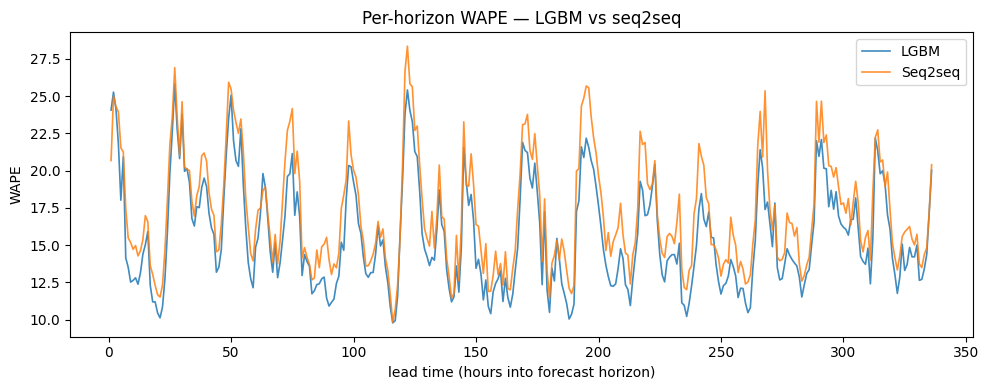


Seq2seq WAPE mean: lead 1-24h = 16.64, lead 169-336h = 17.09, ratio = 1.03
LGBM    WAPE mean: lead 1-24h = 15.22, lead 169-336h = 15.38, ratio = 1.01

✅ Seq2seq WAPE is roughly flat across the horizon — sequence info is being used.


In [9]:
# WAPE binned by lead time. Buckets chosen to cover short, daily, weekly, and full.
BINS = [(1, 1), (2, 6), (7, 24), (25, 72), (73, 168), (169, 336)]

def wape_in_lead_range(df, lo, hi, pred_col):
    f = df[(df["lead_h"] >= lo) & (df["lead_h"] <= hi)]
    return wape(f["target"], f[pred_col]), len(f)

print(f"{'lead-h range':>14}  {'count':>8}  {'WAPE LGBM':>10}  {'WAPE seq2seq':>13}  {'Δ':>7}")
print("-" * 60)
for lo, hi in BINS:
    w_lgbm, n = wape_in_lead_range(joined, lo, hi, "pred_lgbm")
    w_seq,  _ = wape_in_lead_range(joined, lo, hi, "pred_seq")
    label = f"{lo:>3}..{hi:<3}h"
    print(f"  {label:>12}  {n:>8d}    {w_lgbm:>7.3f}      {w_seq:>7.3f}    {w_lgbm - w_seq:>+6.3f}")

# Per-hour WAPE plot — same data but at full resolution
plt.figure(figsize=(10, 4))
per_lead = joined.groupby("lead_h").apply(
    lambda g: pd.Series({
        "wape_lgbm": wape(g["target"], g["pred_lgbm"]),
        "wape_seq":  wape(g["target"], g["pred_seq"]),
    })
).reset_index()
plt.plot(per_lead["lead_h"], per_lead["wape_lgbm"], label="LGBM",     lw=1.2, alpha=0.85)
plt.plot(per_lead["lead_h"], per_lead["wape_seq"],  label="Seq2seq",  lw=1.2, alpha=0.85)
plt.xlabel("lead time (hours into forecast horizon)")
plt.ylabel("WAPE")
plt.title("Per-horizon WAPE — LGBM vs seq2seq")
plt.legend(); plt.tight_layout(); plt.show()

# Diagnostic summary
seq_short = per_lead.loc[per_lead["lead_h"] <= 24, "wape_seq"].mean()
seq_long  = per_lead.loc[per_lead["lead_h"] >= 169, "wape_seq"].mean()
lgbm_short = per_lead.loc[per_lead["lead_h"] <= 24, "wape_lgbm"].mean()
lgbm_long  = per_lead.loc[per_lead["lead_h"] >= 169, "wape_lgbm"].mean()
print()
print(f"Seq2seq WAPE mean: lead 1-24h = {seq_short:.2f}, lead 169-336h = {seq_long:.2f}, "
      f"ratio = {seq_long / seq_short:.2f}")
print(f"LGBM    WAPE mean: lead 1-24h = {lgbm_short:.2f}, lead 169-336h = {lgbm_long:.2f}, "
      f"ratio = {lgbm_long / lgbm_short:.2f}")
print()
if seq_long / seq_short > 1.5:
    print("⚠️  Seq2seq WAPE grows >1.5× from short to long horizon.")
    print("    Model may be under-using sequence structure for distant predictions.")
    print("    Consider: longer encoder context, attention head, or revisit architecture.")
elif seq_long / seq_short < 1.05:
    print("✅ Seq2seq WAPE is roughly flat across the horizon — sequence info is being used.")
else:
    print("~  Seq2seq WAPE shows modest growth — expected for any model on this dataset.")


---
## §9. Joint interpretation — read together with the tabular notebook

This notebook produces one r value (against LightGBM-MAE OOF residuals); the
companion `kp-experiment-7a-tabular.ipynb` produces another. The Phase 7 README
contains the full joint-interpretation table. Quick reference:

| `r_tab` (tabular MLP) | `r_seq` (this notebook) | What it means |
|---|---|---|
| high (>0.95) | high (>0.95) | Signal is feature-bound on both axes. No DL on these inputs will help. Redirect to feature engineering / fold-1 work. |
| high (>0.95) | low (<0.85)  | The seq2seq framing matters specifically. Best signal for going to TiDE / TFT / Chronos-2. |
| low (<0.85)  | low (<0.85)  | Best case — both axes deliver diversity. Test 3-arm ensemble (LGBM + MLP + seq2seq) in experiment-7c. |
| low (<0.85)  | high (>0.95) | Unexpected — investigate the seq2seq run before trusting either. |

The OOF CSVs from both notebooks (`oof_predictions_7a_tabular.csv` and
`oof_predictions_7a_seq2seq.csv`) feed experiment-7c if any of the above
indicates a blend is worth running.
